In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)

from nba_archetypes.config import (
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
)

players = pd.read_parquet(
    PROCESSED_DATA_DIR / "player_style_features.parquet"
).reset_index(drop=True)

offensive_dimensions = [
    "BALL_DOMINANCE",
    "PLAYMAKING",
    "BALL_MOVEMENT",
    "RIM_PRESSURE",
    "ON_BALL_CREATION",
    "PERIMETER_SHOOTING",
    "INTERIOR_OFFENSE",
    "OFFENSIVE_REBOUNDING",
]

offense_cols = [
    f"{name}_SCORE"
    for name in offensive_dimensions
]

X = players[offense_cols].to_numpy()

assert players["PLAYER_ID"].is_unique
assert len(offense_cols) == 8
assert np.isfinite(X).all()

print("Players:", len(players))
print("Offensive dimensions:", X.shape[1])

Players: 450
Offensive dimensions: 8


,PC,Explained Variance,Cumulative Variance
0,1,0.440,0.440
1,2,0.263,0.702
2,3,0.135,0.837
3,4,0.066,0.904
4,5,0.044,0.948
5,6,0.032,0.980
6,7,0.015,0.994
7,8,0.006,1.000


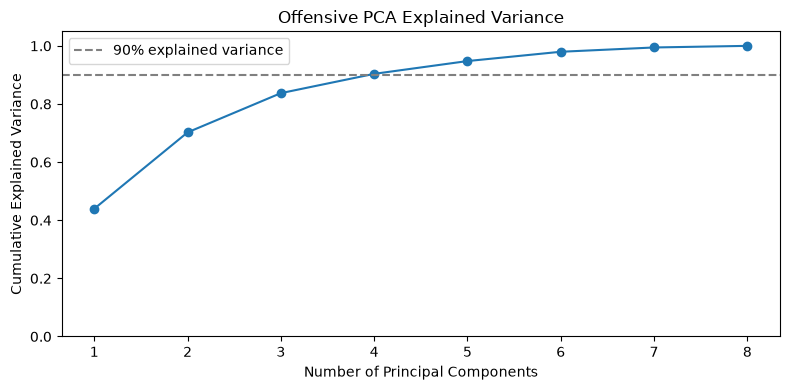

In [4]:
pca = PCA()
pca.fit(X)

pca_summary = pd.DataFrame({
    "PC": range(1, X.shape[1] + 1),
    "Explained Variance": pca.explained_variance_ratio_,
    "Cumulative Variance": np.cumsum(
        pca.explained_variance_ratio_
    ),
})

display(pca_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    pca_summary["PC"],
    pca_summary["Cumulative Variance"],
    marker="o",
)

ax.axhline(
    0.90,
    linestyle="--",
    color="gray",
    label="90% explained variance",
)

ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.set_title("Offensive PCA Explained Variance")
ax.set_xticks(range(1, 9))
ax.set_ylim(0, 1.05)
ax.legend()

plt.tight_layout()
plt.show()

In [5]:
# PCA representations.
X_pca3 = PCA(n_components=3).fit_transform(X)
X_pca4 = PCA(n_components=4).fit_transform(X)

K_VALUES = range(2, 11)

results = []
fitted_models = {}


for k in range(1, 11):

    # Gaussian Mixture Models also support k=1.
    configurations = [
        (
            "GMM diagonal",
            GaussianMixture(
                n_components=k,
                covariance_type="diag",
                reg_covar=1e-4,
                n_init=3,
                random_state=42,
            ),
            X,
        ),
        (
            "GMM full",
            GaussianMixture(
                n_components=k,
                covariance_type="full",
                reg_covar=1e-4,
                n_init=3,
                random_state=42,
            ),
            X,
        ),
    ]

    if k >= 2:
        configurations += [
            (
                "KMeans",
                KMeans(
                    n_clusters=k,
                    n_init=20,
                    random_state=42,
                ),
                X,
            ),
            (
                "KMeans PCA3",
                KMeans(
                    n_clusters=k,
                    n_init=20,
                    random_state=42,
                ),
                X_pca3,
            ),
            (
                "KMeans PCA4",
                KMeans(
                    n_clusters=k,
                    n_init=20,
                    random_state=42,
                ),
                X_pca4,
            ),
            (
                "Agglomerative Ward",
                AgglomerativeClustering(
                    n_clusters=k,
                    linkage="ward",
                ),
                X,
            ),
            (
                "Agglomerative Cosine",
                AgglomerativeClustering(
                    n_clusters=k,
                    linkage="average",
                    metric="cosine",
                ),
                X,
            ),
        ]

    for name, model, X_model in configurations:

        # Fit the model and obtain cluster assignments.
        if isinstance(model, GaussianMixture):
            model.fit(X_model)
            labels = model.predict(X_model)
            bic = model.bic(X_model)
            aic = model.aic(X_model)
        else:
            labels = model.fit_predict(X_model)
            bic = np.nan
            aic = np.nan

        n_groups = len(np.unique(labels))
        sizes = pd.Series(labels).value_counts()

        # k=1 cannot be evaluated with silhouette, DB, or CH.
        if 2 <= n_groups < len(X):
            # All models are evaluated in the original
            # eight-dimensional space for comparability.
            silhouette_euclidean = silhouette_score(
                X, labels, metric="euclidean"
            )

            silhouette_cosine = silhouette_score(
                X, labels, metric="cosine"
            )

            db = davies_bouldin_score(X, labels)
            ch = calinski_harabasz_score(X, labels)

        else:
            silhouette_euclidean = np.nan
            silhouette_cosine = np.nan
            db = np.nan
            ch = np.nan

        results.append({
            "Model": name,
            "k": k,
            "Actual groups": n_groups,
            "Silhouette Euclidean": silhouette_euclidean,
            "Silhouette Cosine": silhouette_cosine,
            "Davies-Bouldin": db,
            "Calinski-Harabasz": ch,
            "BIC": bic,
            "AIC": aic,
            "Inertia": getattr(model, "inertia_", np.nan),
            "Smallest cluster": sizes.min(),
            "Largest cluster": sizes.max(),
        })

        fitted_models[(name, k)] = {
            "model": model,
            "labels": labels,
        }


results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,k,Actual groups,Silhouette Euclidean,Silhouette Cosine,Davies-Bouldin,Calinski-Harabasz,BIC,AIC,Inertia,Smallest cluster,Largest cluster
0,GMM diagonal,1,1,NaN,NaN,NaN,NaN,10314.105,10248.357,NaN,450,450
1,GMM full,1,1,NaN,NaN,NaN,NaN,7687.800,7506.993,NaN,450,450
2,GMM diagonal,2,2,0.277,0.438,1.400,196.294,8996.532,8860.926,NaN,181,269
3,GMM full,2,2,0.223,0.371,1.599,153.808,7390.240,7024.517,NaN,222,228
4,KMeans,2,2,0.294,0.436,1.311,207.238,NaN,NaN,2461.395,154,296
...,...,...,...,...,...,...,...,...,...,...,...,...
60,KMeans,10,10,0.190,0.174,1.394,108.383,NaN,NaN,1119.080,19,78
61,KMeans PCA3,10,10,0.178,0.201,1.450,104.136,NaN,NaN,599.123,22,66
62,KMeans PCA4,10,10,0.180,0.200,1.461,107.078,NaN,NaN,800.964,24,75
63,Agglomerative Ward,10,10,0.138,0.098,1.552,91.512,NaN,NaN,NaN,14,87


Highest Euclidean silhouette:


,Model,k,Actual groups,Silhouette Euclidean,Silhouette Cosine,Davies-Bouldin,Calinski-Harabasz,BIC,AIC,Inertia,Smallest cluster,Largest cluster
5,KMeans PCA3,2,2,0.294,0.435,1.312,207.172,NaN,NaN,1878.061,154,296
4,KMeans,2,2,0.294,0.436,1.311,207.238,NaN,NaN,2461.395,154,296
6,KMeans PCA4,2,2,0.293,0.437,1.316,207.217,NaN,NaN,2115.272,156,294
2,GMM diagonal,2,2,0.277,0.438,1.400,196.294,8996.532,8860.926,NaN,181,269
11,KMeans,3,3,0.273,0.390,1.264,194.879,NaN,NaN,1923.137,93,215
12,KMeans PCA3,3,3,0.271,0.390,1.272,194.741,NaN,NaN,1342.520,96,213
13,KMeans PCA4,3,3,0.271,0.389,1.272,194.732,NaN,NaN,1579.426,96,214
9,GMM diagonal,3,3,0.267,0.367,1.234,180.748,8664.334,8458.872,NaN,71,204
8,Agglomerative Cosine,2,2,0.245,0.408,1.520,170.519,NaN,NaN,NaN,215,235
25,KMeans,5,5,0.224,0.319,1.324,149.096,NaN,NaN,1538.340,67,162


Highest cosine silhouette:


,Model,k,Actual groups,Silhouette Euclidean,Silhouette Cosine,Davies-Bouldin,Calinski-Harabasz,BIC,AIC,Inertia,Smallest cluster,Largest cluster
2,GMM diagonal,2,2,0.277,0.438,1.400,196.294,8996.532,8860.926,NaN,181,269
6,KMeans PCA4,2,2,0.293,0.437,1.316,207.217,NaN,NaN,2115.272,156,294
4,KMeans,2,2,0.294,0.436,1.311,207.238,NaN,NaN,2461.395,154,296
5,KMeans PCA3,2,2,0.294,0.435,1.312,207.172,NaN,NaN,1878.061,154,296
8,Agglomerative Cosine,2,2,0.245,0.408,1.520,170.519,NaN,NaN,NaN,215,235
12,KMeans PCA3,3,3,0.271,0.390,1.272,194.741,NaN,NaN,1342.520,96,213
11,KMeans,3,3,0.273,0.390,1.264,194.879,NaN,NaN,1923.137,93,215
13,KMeans PCA4,3,3,0.271,0.389,1.272,194.732,NaN,NaN,1579.426,96,214
3,GMM full,2,2,0.223,0.371,1.599,153.808,7390.240,7024.517,NaN,222,228
9,GMM diagonal,3,3,0.267,0.367,1.234,180.748,8664.334,8458.872,NaN,71,204


Lowest GMM BIC:


,Model,k,Actual groups,Silhouette Euclidean,Silhouette Cosine,Davies-Bouldin,Calinski-Harabasz,BIC,AIC,Inertia,Smallest cluster,Largest cluster
10,GMM full,3,3,0.178,0.251,1.575,125.569,7347.901,6797.262,NaN,100,195
3,GMM full,2,2,0.223,0.371,1.599,153.808,7390.240,7024.517,NaN,222,228
17,GMM full,4,4,0.131,0.205,1.839,116.158,7498.765,6763.210,NaN,98,128
24,GMM full,5,5,0.112,0.184,2.037,103.906,7648.593,6728.122,NaN,53,123
1,GMM full,1,1,NaN,NaN,NaN,NaN,7687.800,7506.993,NaN,450,450
31,GMM full,6,6,0.111,0.174,1.981,98.152,7822.384,6716.997,NaN,31,144
38,GMM full,7,7,0.079,0.104,2.264,76.670,7952.714,6662.410,NaN,36,150
45,GMM full,8,8,0.109,0.081,1.856,86.258,8177.135,6701.916,NaN,20,120
44,GMM diagonal,8,8,0.160,0.098,1.507,101.930,8210.180,7655.431,NaN,9,95
37,GMM diagonal,7,7,0.154,0.134,1.585,109.303,8223.974,7739.083,NaN,32,107


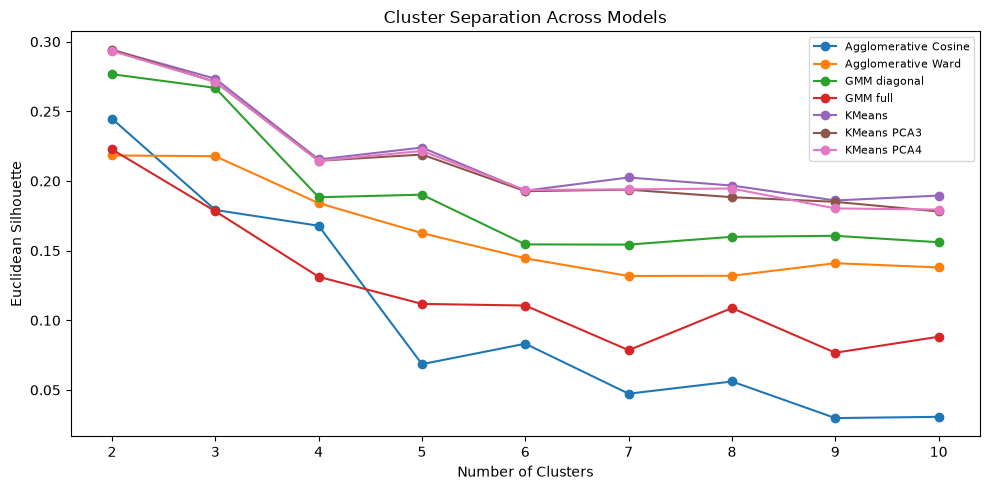

In [6]:
# Best solutions by Euclidean silhouette.
print("Highest Euclidean silhouette:")
display(
    results_df[results_df["k"] >= 2]
    .sort_values("Silhouette Euclidean", ascending=False)
    .head(12)
    .round(3)
)

# Best solutions by cosine silhouette.
print("Highest cosine silhouette:")
display(
    results_df[results_df["k"] >= 2]
    .sort_values("Silhouette Cosine", ascending=False)
    .head(12)
    .round(3)
)

# Best Gaussian Mixtures by BIC.
print("Lowest GMM BIC:")
display(
    results_df[results_df["BIC"].notna()]
    .sort_values("BIC")
    .head(10)
    .round(3)
)

# Compare cluster counts visually.
fig, ax = plt.subplots(figsize=(10, 5))

for model_name, group in results_df[
    results_df["k"] >= 2
].groupby("Model"):

    ax.plot(
        group["k"],
        group["Silhouette Euclidean"],
        marker="o",
        label=model_name,
    )

ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Euclidean Silhouette")
ax.set_title("Cluster Separation Across Models")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [8]:
models = [
    "KMeans",
    "KMeans PCA4",
    "GMM diagonal",
    "Agglomerative Cosine",
]

shortlist = results_df[
    results_df["Model"].isin(models)
    & results_df["k"].between(3, 7)
].copy()


# Compare silhouette scores across models and cluster counts.
silhouette_table = shortlist.pivot(
    index="k",
    columns="Model",
    values="Silhouette Euclidean",
)

display(silhouette_table.round(3))


Model,Agglomerative Cosine,GMM diagonal,KMeans,KMeans PCA4
k,,,,
3,0.179,0.267,0.273,0.271
4,0.168,0.188,0.215,0.214
5,0.069,0.190,0.224,0.222
6,0.083,0.154,0.193,0.194
7,0.047,0.154,0.203,0.194


In [9]:
best_models = []

for name in models:

    subset = shortlist[
        shortlist["Model"] == name
    ]

    if name == "GMM diagonal":
        best_idx = subset["BIC"].idxmin()
    else:
        best_idx = subset["Silhouette Euclidean"].idxmax()

    best_models.append(shortlist.loc[best_idx])


best_models_df = pd.DataFrame(best_models)

display(
    best_models_df[
        [
            "Model",
            "k",
            "Silhouette Euclidean",
            "Davies-Bouldin",
            "Smallest cluster",
            "BIC",
        ]
    ].round(3)
)


,Model,k,Silhouette Euclidean,Davies-Bouldin,Smallest cluster,BIC
11,KMeans,3,0.273,1.264,93,NaN
13,KMeans PCA4,3,0.271,1.272,96,NaN
37,GMM diagonal,7,0.154,1.585,32,8223.974
15,Agglomerative Cosine,3,0.179,1.455,52,NaN


In [10]:
# Isolate the original KMeans results.
kmeans_results = (
    results_df[
        (results_df["Model"] == "KMeans")
        & (results_df["k"].between(2, 8))
    ]
    .sort_values("k")
    .copy()
)

# Display the metrics relevant to KMeans.
display(
    kmeans_results[
        [
            "k",
            "Inertia",
            "Silhouette Euclidean",
            "Davies-Bouldin",
            "Calinski-Harabasz",
            "Smallest cluster",
            "Largest cluster",
        ]
    ].round(3)
)

,k,Inertia,Silhouette Euclidean,Davies-Bouldin,Calinski-Harabasz,Smallest cluster,Largest cluster
4,2,2461.395,0.294,1.311,207.238,154,296
11,3,1923.137,0.273,1.264,194.879,93,215
18,4,1702.948,0.215,1.471,165.612,81,163
25,5,1538.340,0.224,1.324,149.096,67,162
32,6,1410.639,0.193,1.463,137.821,62,96
39,7,1311.972,0.203,1.414,128.762,29,97
46,8,1227.869,0.197,1.449,121.986,30,88


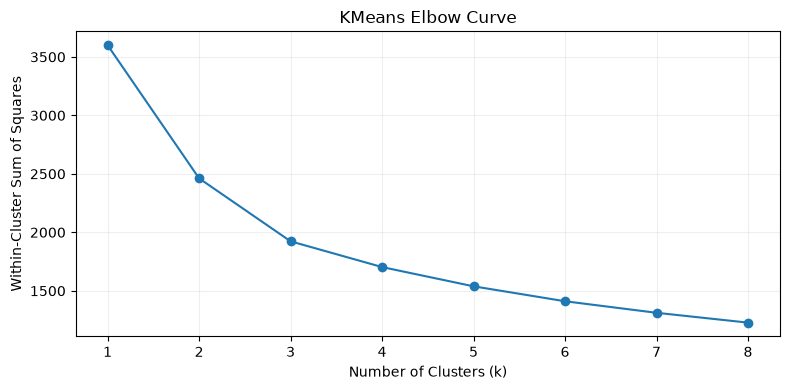

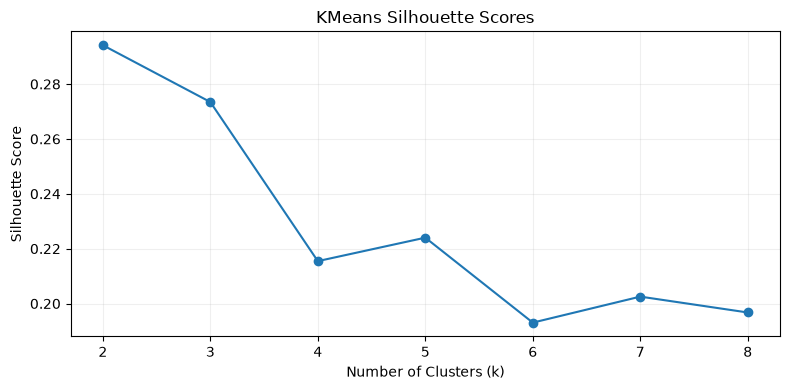

In [11]:
k1_model = KMeans(
    n_clusters=1,
    n_init=20,
    random_state=42,
).fit(X)

elbow_k = [1] + kmeans_results["k"].tolist()

elbow_inertia = [
    k1_model.inertia_
] + kmeans_results["Inertia"].tolist()


# Elbow curve.
plt.figure(figsize=(8, 4))

plt.plot(
    elbow_k,
    elbow_inertia,
    marker="o",
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares")
plt.title("KMeans Elbow Curve")
plt.xticks(elbow_k)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# Silhouette curve.
plt.figure(figsize=(8, 4))

plt.plot(
    kmeans_results["k"],
    kmeans_results["Silhouette Euclidean"],
    marker="o",
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("KMeans Silhouette Scores")
plt.xticks(kmeans_results["k"])
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [12]:
for k in [3, 5, 7]:

    labels = fitted_models[("KMeans", k)]["labels"]

    comparison = players[
        ["PLAYER_ID", "PLAYER_NAME"] + offense_cols
    ].copy()

    comparison["cluster"] = labels

    profiles = (
        comparison.groupby("cluster")[offense_cols]
        .mean()
    )

    print(f"\nKMeans with k={k}")

    print("Cluster sizes:")
    display(
        comparison["cluster"]
        .value_counts()
        .sort_index()
    )

    print("Mean dimension scores:")
    display(profiles.round(2))



KMeans with k=3
Cluster sizes:


cluster
0     93
1    215
2    142
Name: count, dtype: int64

Mean dimension scores:


,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
cluster,,,,,,,,
0,-0.68,-0.62,0.01,0.09,-0.77,-1.20,1.41,1.07
1,-0.50,-0.44,0.22,-0.62,-0.45,0.65,-0.31,-0.09
2,1.20,1.07,-0.35,0.88,1.18,-0.20,-0.45,-0.56



KMeans with k=5
Cluster sizes:


cluster
0     77
1     67
2     70
3     74
4    162
Name: count, dtype: int64

... (2 outputs left out)


KMeans with k=7
Cluster sizes:


cluster
0    29
1    97
2    58
3    63
4    53
5    80
6    70
Name: count, dtype: int64

Mean dimension scores:


,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
cluster,,,,,,,,
0,0.72,0.44,-0.67,1.32,0.24,-1.05,1.52,-0.12
1,-0.72,-0.64,0.25,-0.38,-0.73,0.23,0.18,0.55
2,-0.92,-0.71,0.13,-0.08,-0.90,-1.59,1.57,1.48
3,1.67,1.56,-0.56,1.39,1.60,-0.37,-0.63,-0.59
4,0.61,0.95,1.14,-0.31,0.56,0.26,-0.72,-0.42
5,-0.71,-0.59,0.25,-1.12,-0.61,1.16,-0.66,-0.46
6,0.32,-0.14,-0.83,0.29,0.48,0.24,-0.32,-0.57


In [14]:
labels_3 = fitted_models[("KMeans", 3)]["labels"]
labels_5 = fitted_models[("KMeans", 5)]["labels"]
labels_7 = fitted_models[("KMeans", 7)]["labels"]

cluster_comparison = pd.crosstab(
    index=pd.Series(labels_3, name="k=3"),
    columns=[
        pd.Series(labels_5, name="k=5"),
        pd.Series(labels_7, name="k=7"),
    ],
)
display(cluster_comparison)
# Percentage of each k=3 group assigned to each k=5 group.
display(
    cluster_comparison.div(
        cluster_comparison.sum(axis=1),
        axis=0,
    ).mul(100).round(1)
)


k=5  0          1      2               3           4    
k=7  0  1   6   0   3  0  1  3   4  6  0   1   2   1   5
k=3                                                     
0    8  1   0   0   0  1  0  0   1  0  6  10  58   8   0
1    0  2  36   0   0  0  2  0  20  1  0   0   0  74  80
2    2  0  28  11  56  1  0  7  32  5  0   0   0   0   0

k=5    0               1          2                         3              \
k=7    0    1     6    0     3    0    1    3     4    6    0     1     2   
k=3                                                                         
0    8.6  1.1   0.0  0.0   0.0  1.1  0.0  0.0   1.1  0.0  6.5  10.8  62.4   
1    0.0  0.9  16.7  0.0   0.0  0.0  0.9  0.0   9.3  0.5  0.0   0.0   0.0   
2    1.4  0.0  19.7  7.7  39.4  0.7  0.0  4.9  22.5  3.5  0.0   0.0   0.0   

k=5     4        
k=7     1     5  
k=3              
0     8.6   0.0  
1    34.4  37.2  
2     0.0   0.0

In [15]:
labels_5 = fitted_models[("KMeans", 5)]["labels"]
labels_7 = fitted_models[("KMeans", 7)]["labels"]

model_7 = fitted_models[("KMeans", 7)]["model"]

# Clearer membership comparison.
display(
    pd.crosstab(
        pd.Series(labels_5, name="k=5"),
        pd.Series(labels_7, name="k=7"),
    )
)

# Examine representative players from the key new groups.
for cluster in [0, 1, 5]:

    indices = np.where(labels_7 == cluster)[0]

    center = model_7.cluster_centers_[cluster]

    distances = np.linalg.norm(
        X[indices] - center,
        axis=1,
    )

    closest = indices[np.argsort(distances)[:10]]

    representatives = players.iloc[closest][
        ["PLAYER_NAME", "USG_PCT"]
    ].copy()

    representatives["Previous k=5 Cluster"] = (
        labels_5[closest]
    )

    representatives["Centroid Distance"] = (
        distances[np.argsort(distances)[:10]]
    )

    print(f"\nk=7 Cluster {cluster}")
    display(representatives.round(3))

k=7,0,1,2,3,4,5,6
k=5,,,,,,,
0,10,3,0,0,0,0,64
1,11,0,0,56,0,0,0
2,2,2,0,7,53,0,6
3,6,10,58,0,0,0,0
4,0,82,0,0,0,80,0



k=7 Cluster 0


,PLAYER_NAME,USG_PCT,Previous k=5 Cluster,Centroid Distance
210,Jimmy Butler III,0.226,1,1.126
11,Alex Sarr,0.252,0,1.140
132,Evan Mobley,0.221,0,1.379
239,Julius Randle,0.258,1,1.384
103,Derik Queen,0.214,1,1.523
331,Nic Claxton,0.175,3,1.598
353,Paolo Banchero,0.274,1,1.604
354,Pascal Siakam,0.292,1,1.632
21,Anthony Davis,0.272,0,1.649
12,Alperen Sengun,0.259,1,1.692



k=7 Cluster 1


,PLAYER_NAME,USG_PCT,Previous k=5 Cluster,Centroid Distance
270,Kobe Brown,0.154,4,0.541
161,Jabari Walker,0.142,4,0.804
104,Derrick Jones Jr.,0.144,4,0.821
185,Jamir Watkins,0.148,4,0.960
388,Santi Aldama,0.191,4,0.995
25,Asa Newell,0.160,4,1.009
311,Micah Peavy,0.135,4,1.034
380,Ryan Dunn,0.136,4,1.050
410,Tidjane Salaün,0.147,4,1.050
150,Isaac Okoro,0.137,4,1.066



k=7 Cluster 5


,PLAYER_NAME,USG_PCT,Previous k=5 Cluster,Centroid Distance
283,Landry Shamet,0.151,4,0.606
258,Keon Ellis,0.129,4,0.680
131,Ethan Thompson,0.154,4,0.684
401,Svi Mykhailiuk,0.143,4,0.703
146,Harrison Barnes,0.144,4,0.703
386,Sam Merrill,0.167,4,0.810
436,Vít Krejčí,0.142,4,0.814
235,Julian Champagnie,0.146,4,0.853
319,Mohamed Diawara,0.169,4,0.870
241,Justin Edwards,0.154,4,0.899
